# Report statistico 2: metodi, modelli e architetture — la resa vale la spesa?

Per ogni componente del progetto si confronta il **guadagno di accuracy** (con test di significatività appaiati sulle stesse battaglie) con il **costo** (tempo di calcolo sul Mac M5 a 10 core, complessità). Componenti analizzati:

1. i 22 base model dello stack;
2. il meta-modello rispetto alla media e al miglior modello singolo;
3. la selezione di un sottoinsieme di modelli con una procedura annidata (stack ridotto);
4. i blocchi di feature e le architetture (Monte Carlo, modello ricorsivo, augmentation, matchup strategici, storia per pokemon, esperti di regime);
5. le politiche di fold e ripetizioni.

Costo misurato dai log delle run (`outputs/folds_experiment_log.txt` e i tempi delle singole pipeline sul M5). Le stime di accuratezza sono OOF (5-fold, seed 42) o annidate (`src/evaluate_nested.py`).

In [1]:
import os, sys, json, hashlib, warnings
from collections import Counter
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from scipy.special import logit
from sklearn.metrics import roc_auc_score
warnings.filterwarnings("ignore")
ROOT = os.path.abspath("..") if os.path.basename(os.getcwd()) == "reports" else os.getcwd()
os.chdir(ROOT); sys.path.insert(0, os.path.join(ROOT, "src"))
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .3})
RNG = np.random.default_rng(0)

def wilson(k, n, z=1.96):
    """Intervallo di Wilson al 95% per una proporzione."""
    p = k / n; d = 1 + z**2 / n
    c = (p + z**2 / (2 * n)) / d; h = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / d
    return c - h, c + h

def mcnemar(a_ok, b_ok):
    """Test di McNemar esatto su due vettori di correttezza appaiati."""
    b = int((a_ok & ~b_ok).sum()); c = int((~a_ok & b_ok).sum())
    p = stats.binomtest(min(b, c), b + c, 0.5).pvalue if b + c else 1.0
    return b, c, p

def paired_bootstrap(a_ok, b_ok, n=5000):
    """IC al 95% della differenza di accuracy (b - a) ricampionando le battaglie."""
    d = b_ok.astype(float) - a_ok.astype(float)
    idx = RNG.integers(0, len(d), (n, len(d)))
    bs = d[idx].mean(1)
    return d.mean(), np.percentile(bs, 2.5), np.percentile(bs, 97.5)

In [2]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import RepeatedStratifiedKFold, StratifiedKFold
F = pd.read_pickle("outputs/features.pkl")
y = F[F.is_test == 0].player_won.values.astype(int)

def load_oof(d, names=None):
    names = names or sorted(f[:-4] for f in os.listdir(d) if f.endswith(".npz"))
    return {n: np.load(f"{d}/{n}.npz") for n in names}

def to_Z(P, names):
    return np.column_stack([logit(np.clip(P[n]["oof"], 1e-4, 1 - 1e-4)) for n in names])

def meta_cv(Z, y, repeats=5, seed=43):
    """Meta logreg sui logit: (acc media dei fold, sd, predizione OOF mediata sulle ripetizioni)."""
    accs, pm = [], np.zeros(len(y))
    for a, b in RepeatedStratifiedKFold(n_splits=5, n_repeats=repeats, random_state=seed).split(Z, y):
        p = LogisticRegression(C=1.0, max_iter=2000).fit(Z[a], y[a]).predict_proba(Z[b])[:, 1]
        pm[b] += p / repeats; accs.append(((p > .5) == y[b]).mean())
    return np.mean(accs), np.std(accs), pm

# tempi per modello (secondi, 5 fold) dalla run che ha prodotto outputs/oof_mc_rec
def parse_times(path):
    secs, sec, out = {}, None, {}
    for line in open(path):
        if line.startswith("=="): sec = line.strip("= \n")
        elif "OOF acc" in line and "|" in line:
            out.setdefault(sec, {})[line.split()[0]] = int(line.rsplit("|", 1)[1].strip().rstrip("s"))
        elif line.startswith("real") and sec: secs[sec] = float(line.split()[1])
    return out, secs
TIMES, TOTALS = parse_times("outputs/folds_experiment_log.txt")
T = TIMES["stacking folds=5 repeats=1"]
P = load_oof("outputs/oof_mc_rec"); names = sorted(P)
Z = to_Z(P, names)
print(f"{len(names)} base model; tempo totale dei base model {sum(T.values())/60:.1f} min")

22 base model; tempo totale dei base model 9.5 min


## 1. I base model: accuratezza, overfitting e costo

`gap` = accuracy sul train − accuracy OOF (misura di overfitting). Il costo è il tempo per calcolare le 5 OOF più le predizioni di test.

In [3]:
rows = []
for n in names:
    p = P[n]["oof"]; ok = (p > .5) == y
    rows.append((n, ok.mean(), roc_auc_score(y, p), float(P[n]["train_acc"]) - ok.mean(), T.get(n, np.nan)))
B = pd.DataFrame(rows, columns=["modello", "acc OOF", "AUC", "gap", "tempo s"]).sort_values("acc OOF", ascending=False)
B.style.format({"acc OOF": "{:.4f}", "AUC": "{:.4f}", "gap": "{:+.3f}", "tempo s": "{:.0f}"}).background_gradient(subset=["acc OOF"], cmap="Greens")

,modello,acc OOF,AUC,gap,tempo s
20,xgb_aug,0.6919,0.7602,+0.090,32
21,xgb_noise,0.6904,0.7606,+0.096,30
4,extratrees,0.6894,0.7546,+0.311,56
10,lgbm_aug,0.6893,0.7605,+0.107,23
1,catboost_aug,0.6890,0.7573,+0.265,93
19,xgb,0.6887,0.7587,+0.115,13
12,lgbm_dense_aug,0.6884,0.7566,+0.100,16
3,catboost_dense_aug,0.6875,0.7538,+0.261,50
17,rf,0.6873,0.7480,+0.310,47
11,lgbm_dense,0.6871,0.7562,+0.131,11


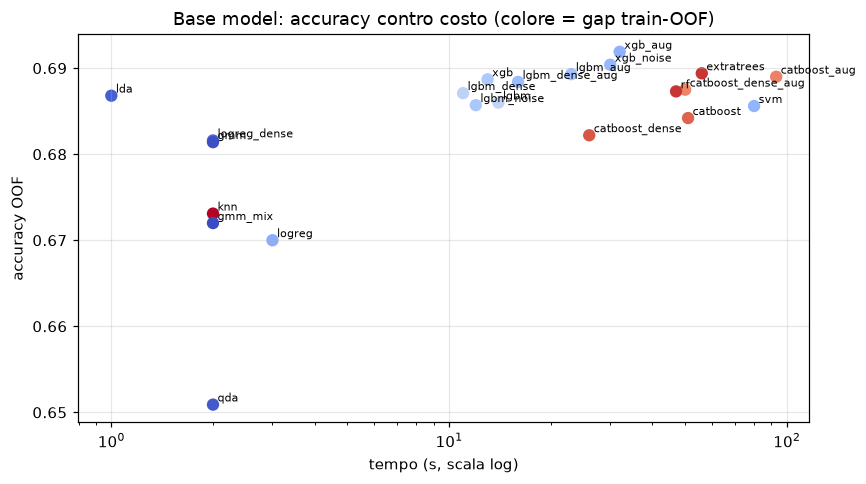

In [4]:
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.scatter(B["tempo s"], B["acc OOF"], c=B.gap, cmap="coolwarm", s=50)
for _, r in B.iterrows(): ax.annotate(r.modello, (r["tempo s"], r["acc OOF"]), fontsize=7, xytext=(3, 2), textcoords="offset points")
ax.set_xscale("log"); ax.set(xlabel="tempo (s, scala log)", ylabel="accuracy OOF", title="Base model: accuracy contro costo (colore = gap train-OOF)")
plt.tight_layout(); plt.show()

**Lettura:** quasi tutti i modelli stanno in una fascia stretta (0.68-0.69) a costi che variano di due ordini di grandezza. I modelli lineari e generativi (lda, logreg_dense, gmm) costano secondi e quasi non vanno in overfitting; CatBoost, ExtraTrees, RF e SVM costano minuti senza essere più accurati da soli. Il loro valore va però misurato dentro lo stack (sezione 4): un modello meno accurato ma diverso può servire più di uno accurato e ridondante.

## 2. Il meta-modello serve? Stack contro media e contro il miglior modello singolo

Confronti appaiati sulle stesse 10000 battaglie: differenza di accuracy con IC bootstrap e test di McNemar.

In [5]:
acc_s, sd_s, pm = meta_cv(Z, y)
stack_ok = (pm > .5) == y
best = B.iloc[0].modello
refs = {f"miglior singolo ({best})": (P[best]["oof"] > .5) == y,
        "media dei logit (22)": (Z.mean(1) > 0) == y,
        "lgbm da solo": (P["lgbm"]["oof"] > .5) == y,
        "logreg da sola": (P["logreg"]["oof"] > .5) == y}
rows = []
for nm, ok in refs.items():
    d, lo, hi = paired_bootstrap(ok, stack_ok); b, c, p = mcnemar(ok, stack_ok)
    rows.append((nm, ok.mean(), d, lo, hi, c, b, p))
print(f"stack (meta logreg, 22 modelli): {acc_s:.4f} ± {sd_s:.4f} (5x5 CV)")
pd.DataFrame(rows, columns=["riferimento", "acc", "guadagno stack", "IC lo", "IC hi", "corrette solo dallo stack", "solo dal rif.", "McNemar p"]).style.format(
    {"acc": "{:.4f}", "guadagno stack": "{:+.4f}", "IC lo": "{:+.4f}", "IC hi": "{:+.4f}", "McNemar p": "{:.3f}"})

stack (meta logreg, 22 modelli): 0.6981 ± 0.0106 (5x5 CV)


,riferimento,acc,guadagno stack,IC lo,IC hi,corrette solo dallo stack,solo dal rif.,McNemar p
0,miglior singolo (xgb_aug),0.6919,+0.0060,+0.0004,+0.0117,433,373,0.038
1,media dei logit (22),0.6948,+0.0031,-0.0015,+0.0076,282,251,0.194
2,lgbm da solo,0.6860,+0.0119,+0.0061,+0.0176,495,376,0.000
3,logreg da sola,0.6700,+0.0279,+0.0205,+0.0351,878,599,0.000


**Lettura:** lo stack batte in modo significativo ogni modello singolo, compreso il migliore (xgb_aug, +0.6 punti, p ≈ 0.04), ma **non** si distingue in modo significativo dalla semplice media dei logit (+0.3 punti, p ≈ 0.19). Il meta-modello costa secondi, quindi conviene comunque; la gran parte del guadagno viene però dall'ensemble in sé, non dai pesi appresi.

## 3. Diversità dei modelli: correlazione degli errori

Lo stacking guadagna solo se i modelli sbagliano su battaglie diverse. Correlazione tra i residui (y − p) delle OOF, ordinata per clustering gerarchico.

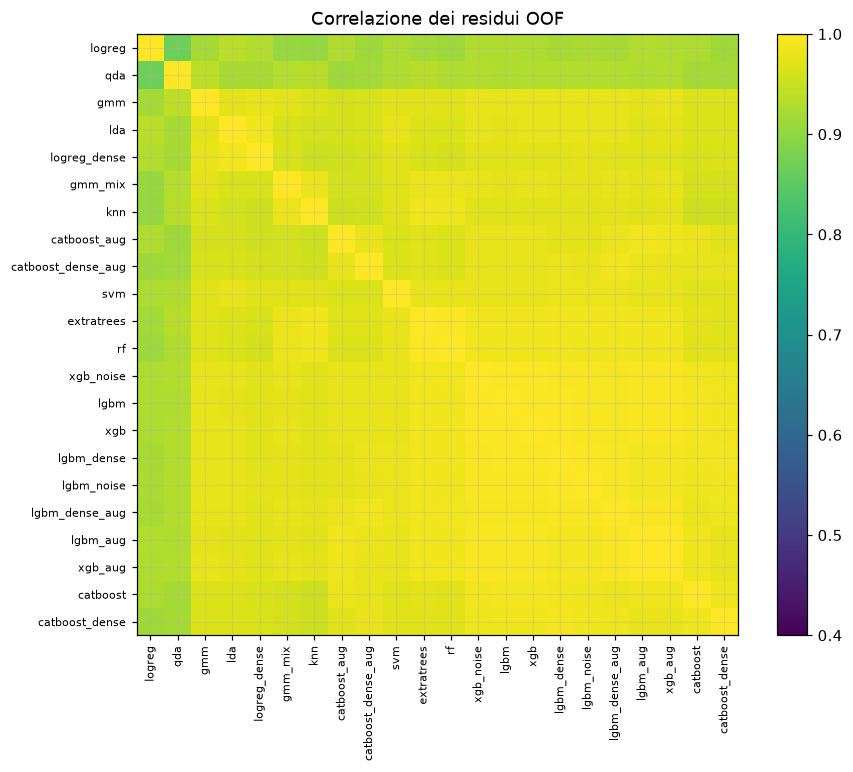

correlazione media dei residui: 0.97 (min 0.87, max 1.00)


In [6]:
from scipy.cluster.hierarchy import linkage, leaves_list
R = np.column_stack([y - P[n]["oof"] for n in names])
C = np.corrcoef(R.T)
order = leaves_list(linkage(R.T, "average", metric="correlation"))
fig, ax = plt.subplots(figsize=(8.5, 7))
im = ax.imshow(C[np.ix_(order, order)], cmap="viridis", vmin=.4, vmax=1)
ax.set_xticks(range(len(names))); ax.set_xticklabels(np.array(names)[order], rotation=90, fontsize=7)
ax.set_yticks(range(len(names))); ax.set_yticklabels(np.array(names)[order], fontsize=7)
plt.colorbar(im); ax.set_title("Correlazione dei residui OOF"); plt.tight_layout(); plt.show()
off = C[np.triu_indices(len(names), 1)]
print(f"correlazione media dei residui: {off.mean():.2f} (min {off.min():.2f}, max {off.max():.2f})")

## 4. Valore marginale di ogni modello nello stack (ablazione)

Per ogni base model si rifà il meta senza di lui, sugli **stessi split** (5×5): un valore negativo significa che toglierlo peggiora lo stack. Il rapporto con il tempo dice quanto costa ogni decimo di punto.

In [7]:
splits = list(RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=43).split(Z, y))
def acc_on(cols):
    return np.array([((LogisticRegression(C=1.0, max_iter=2000).fit(Z[a][:, cols], y[a]).predict_proba(Z[b][:, cols])[:, 1] > .5) == y[b]).mean()
                     for a, b in splits])
full = acc_on(list(range(len(names))))
rows = []
for i, n in enumerate(names):
    d = acc_on([j for j in range(len(names)) if j != i]) - full
    rows.append((n, -d.mean(), d.std(ddof=1) / np.sqrt(len(d)), T.get(n, np.nan)))
A = pd.DataFrame(rows, columns=["modello", "contributo", "se", "tempo s"]).sort_values("contributo", ascending=False)
A["punti per minuto"] = A.contributo * 100 / (A["tempo s"] / 60)
print(f"stack completo: {full.mean():.4f}")
A.style.format({"contributo": "{:+.4f}", "se": "{:.4f}", "tempo s": "{:.0f}", "punti per minuto": "{:+.3f}"}).bar(subset=["contributo"], align="zero", color=["#d65f5f", "#5fba7d"])

stack completo: 0.6981


,modello,contributo,se,tempo s,punti per minuto
4,extratrees,+0.0029,0.0009,56,+0.311
1,catboost_aug,+0.0017,0.0005,93,+0.111
17,rf,+0.0014,0.0004,47,+0.181
3,catboost_dense_aug,+0.0011,0.0005,50,+0.132
12,lgbm_dense_aug,+0.0010,0.0004,16,+0.360
15,logreg_dense,+0.0008,0.0006,2,+2.400
21,xgb_noise,+0.0005,0.0005,30,+0.096
7,knn,+0.0004,0.0004,2,+1.200
14,logreg,+0.0004,0.0005,3,+0.720
16,qda,+0.0004,0.0004,2,+1.080


**Lettura:**

- I residui sono correlati in media 0.97: i modelli sbagliano quasi sempre sulle stesse battaglie, e ogni contributo individuale è piccolo (al massimo +0.3 punti).
- Contro l'intuizione della sezione 1, i modelli che contribuiscono di più sono proprio alcuni dei **più costosi e meno accurati da soli**: ExtraTrees, RF e i CatBoost con augmentation. Sono i più diversi dai boosting (bagging con alberi profondi), e la loro diversità vale più della loro accuratezza.
- Hanno contributo nullo o negativo i modelli ridondanti con altri: lgbm, xgb, svm, catboost e catboost_dense senza augmentation, i GMM, lgbm_noise.
- Avvertenza: l'errore standard viene da 25 split ripetuti degli stessi dati, quindi è sottostimato; differenze sotto ~0.1 punti vanno considerate nulle.

## 5. Uno stack ridotto è altrettanto buono? Selezione annidata

Selezione in avanti (greedy) dei base model **dentro** ogni fold esterno: si sceglie sul training esterno con una CV interna e si valuta sul fold esterno mai visto. Così la stima non è ottimistica (la selezione greedy fatta sulla stessa CV darebbe numeri gonfiati). Si ferma quando aggiungere un modello migliora la CV interna di meno di 0.05 punti.

In [8]:
def greedy(Zt, yt, max_k=8, tol=5e-4, seed=7):
    sp = list(StratifiedKFold(5, shuffle=True, random_state=seed).split(Zt, yt))
    def score(cols):
        return np.mean([((LogisticRegression(C=1.0, max_iter=2000).fit(Zt[a][:, cols], yt[a]).predict_proba(Zt[b][:, cols])[:, 1] > .5) == yt[b]).mean() for a, b in sp])
    chosen, cur = [], 0.0
    while len(chosen) < max_k:
        cand = [(score(chosen + [j]), j) for j in range(Zt.shape[1]) if j not in chosen]
        s, j = max(cand)
        if s - cur < tol: break
        chosen.append(j); cur = s
    return chosen

outer = StratifiedKFold(5, shuffle=True, random_state=42)
p_small, p_full, picks = np.zeros(len(y)), np.zeros(len(y)), []
for a, b in outer.split(Z, y):
    cols = greedy(Z[a], y[a]); picks.append([names[j] for j in cols])
    p_small[b] = LogisticRegression(C=1.0, max_iter=2000).fit(Z[a][:, cols], y[a]).predict_proba(Z[b][:, cols])[:, 1]
    p_full[b] = LogisticRegression(C=1.0, max_iter=2000).fit(Z[a], y[a]).predict_proba(Z[b])[:, 1]
ok_s, ok_f = (p_small > .5) == y, (p_full > .5) == y
d, lo, hi = paired_bootstrap(ok_f, ok_s); _, _, pv = mcnemar(ok_f, ok_s)
cnt = Counter(m for p in picks for m in p)
t_small = np.mean([sum(T[m] for m in p) for p in picks])
print(f"stack completo (22): {ok_f.mean():.4f}, tempo base model {sum(T.values())/60:.1f} min")
print(f"stack ridotto (in media {np.mean([len(p) for p in picks]):.1f} modelli): {ok_s.mean():.4f}, tempo {t_small/60:.1f} min")
print(f"differenza ridotto - completo: {d*100:+.2f} punti, IC95% [{lo*100:+.2f}, {hi*100:+.2f}], McNemar p = {pv:.2f}")
print("modelli scelti (fold esterni su 5):", dict(cnt.most_common()))

stack completo (22): 0.6986, tempo base model 9.5 min
stack ridotto (in media 2.6 modelli): 0.6924, tempo 1.5 min
differenza ridotto - completo: -0.62 punti, IC95% [-1.13, -0.11], McNemar p = 0.02
modelli scelti (fold esterni su 5): {'xgb_aug': 4, 'catboost_dense_aug': 3, 'lgbm_aug': 2, 'svm': 1, 'xgb_noise': 1, 'xgb': 1, 'lda': 1}


La selezione greedy si ferma troppo presto. Confronto anche alcuni sottoinsiemi fissati, sugli stessi split dello stack completo. I primi due sono decisi solo in base al costo, quindi la stima è onesta. Gli ultimi due sono suggeriti dall'ablazione della sezione 4, fatta sugli stessi dati: la loro stima è leggermente ottimistica e va confermata con una valutazione annidata.

In [9]:
subsets = {
    "economici (<= 20 s ciascuno)": [n for n in names if T[n] <= 20],
    "4 classici (logreg, lgbm, xgb, catboost)": ["logreg", "lgbm", "xgb", "catboost"],
    "senza svm e senza i catboost non _aug": [n for n in names if n not in ("svm", "catboost", "catboost_dense")],
    "solo boosting _aug + ET + RF + lineari": [n for n in names if n.endswith("_aug") or n in ("extratrees", "rf", "lda", "logreg", "logreg_dense")],
}
rows = []
for nm, ms in subsets.items():
    cols = [names.index(m) for m in ms]
    _, _, p_ = meta_cv(Z[:, cols], y)
    ok = (p_ > .5) == y
    d, lo, hi = paired_bootstrap(stack_ok, ok); _, _, pv = mcnemar(stack_ok, ok)
    t = sum(T[m] for m in ms)
    rows.append((nm, len(ms), acc_on(cols).mean(), d * 100, lo * 100, hi * 100, pv, t / 60, 1 - t / sum(T.values())))
SUB = pd.DataFrame(rows, columns=["sottoinsieme", "modelli", "acc", "Δ vs 22", "IC lo", "IC hi", "McNemar p", "tempo min", "risparmio"])
SUB.style.format({"acc": "{:.4f}", "Δ vs 22": "{:+.2f}", "IC lo": "{:+.2f}", "IC hi": "{:+.2f}", "McNemar p": "{:.3f}", "tempo min": "{:.1f}", "risparmio": "{:.0%}"})

,sottoinsieme,modelli,acc,Δ vs 22,IC lo,IC hi,McNemar p,tempo min,risparmio
0,economici (<= 20 s ciascuno),12,0.6915,-0.58,-1.02,-0.14,0.010,1.3,86%
1,"4 classici (logreg, lgbm, xgb, catboost)",4,0.6879,-0.94,-1.45,-0.43,0.000,1.4,86%
2,senza svm e senza i catboost non _aug,19,0.6993,+0.09,-0.13,+0.32,0.491,6.8,28%
3,solo boosting _aug + ET + RF + lineari,10,0.6994,+0.15,-0.14,+0.45,0.355,5.4,43%


**Lettura:**

- Ridurre lo stack ai modelli economici o ai 4 classici costa in modo **significativo** (−0.6 / −0.9 punti), e lo stesso vale per la selezione greedy annidata (−0.6 punti, p ≈ 0.02). Il risparmio di tempo (86%) si paga in accuratezza.
- Togliere i modelli ridondanti (svm, catboost senza augmentation, lgbm/xgb/gmm) non peggiora: con 10 modelli e il 43% di tempo in meno l'accuratezza è uguale (+0.15, non significativo).
- Quindi la diversità serve, la quantità no: conviene tenere i modelli diversi (boosting con augmentation, ExtraTrees, RF, lineari) e togliere i duplicati.

## 6. Blocchi di feature e architetture

Ogni riga confronta una variante con la propria baseline **sugli stessi fold e sulle stesse battaglie**:

- **Monte Carlo e ricorsivo** (feature v3, 17 base model; e singoli modelli lgbm/xgb/lda/gmm/logreg_dense): OOF standard, meta rifatto qui con gli stessi split.
- **Augmentation** (modelli `_aug`, v4): stack v4 con e senza i 5 modelli `_aug`.
- **Matchup strategici, storia per pokemon, esperti di regime, pesi dell'augmentation:** stime annidate di `evaluate_nested.py` (4 o 3 base model).
- **Strat + lon nello stack completo a 22 modelli.**

Il costo è il tempo aggiuntivo della pipeline (generazione delle feature, più il tempo di training dei modelli in più).

In [10]:
def compare_stacks(Pa, Pb, names_a, names_b):
    _, _, pa = meta_cv(to_Z(Pa, names_a), y); _, _, pb = meta_cv(to_Z(Pb, names_b), y)
    return (pa > .5) == y, (pb > .5) == y

def nested_ok(name):
    d = pd.read_csv(f"outputs/experiments/{name}/predictions.csv").set_index("battle_id").sort_index()
    return (d.pred == d.y_true).values

rows = []
def add(label, ok_a, ok_b, cost_s, kind):
    d, lo, hi = paired_bootstrap(ok_a, ok_b); _, _, p = mcnemar(ok_a, ok_b)
    rows.append((label, kind, ok_a.mean(), ok_b.mean(), d * 100, lo * 100, hi * 100, p, cost_s))

# Monte Carlo + ricorsivo sullo stack v3 a 17 modelli (stessi fold)
v3, v3mr = load_oof("outputs/oof_v3"), load_oof("outputs/oof_v3_mc_rec")
add("Monte Carlo + ricorsivo (stack 17)", *compare_stacks(v3, v3mr, sorted(v3), sorted(v3)), 190 + 122, "OOF")
for extra, cost in (("mc", 190), ("rec", 122)):
    Pe = load_oof(f"outputs/oof_v3_{extra}"); ms = sorted(Pe)
    add(f"{'Monte Carlo' if extra == 'mc' else 'ricorsivo'} da solo (stack {len(ms)})", *compare_stacks(v3, Pe, ms, ms), cost, "OOF")
# augmentation: stack v4 senza/con i modelli _aug (stesse feature)
v4 = load_oof("outputs/oof_v4a", [n for n in names if n in os.listdir("outputs/oof_v4a") or f"{n}.npz" in os.listdir("outputs/oof_v4a")]); no_aug = sorted(n for n in v4 if "_aug" not in n)
aug_names = sorted(n for n in v4 if "_aug" in n)
add(f"augmentation ({len(aug_names)} modelli _aug)", *compare_stacks(v4, v4, no_aug, sorted(v4)), sum(T[n] for n in aug_names), "OOF")
# strat + lon nello stack completo
Psl = load_oof("outputs/oof_mc_rec_strat_lon")
add("strat + lon (stack 22)", *compare_stacks(P, Psl, names, names), 121 + 14, "OOF")
# esperimenti annidati
base4 = nested_ok("nested_base4")
for name, label, cost in (("nested_base4_strat", "matchup strategici + P(KO) + pool", 121),
                          ("nested_base4_strat_nopool", "matchup strategici senza pool", 121),
                          ("nested_base4_lon", "storia per pokemon", 14),
                          ("nested_base4_strat_lon", "strategici + storia", 135),
                          ("nested_base4_exp", "esperti di regime", 3 * 15),
                          ("nested_base4_exp_gate", "esperti + gating", 3 * 15)):
    add(label, base4, nested_ok(name), cost, "annidata")
w5 = nested_ok("nested_aug_w0.5")
for w in ("0.25", "1.0"):
    add(f"peso augmentation {w} (contro 0.5)", w5, nested_ok(f"nested_aug_w{w}"), 0, "annidata")
D = pd.DataFrame(rows, columns=["componente", "stima", "acc base", "acc con", "Δ punti", "IC lo", "IC hi", "McNemar p", "costo s"])
D.style.format({"acc base": "{:.4f}", "acc con": "{:.4f}", "Δ punti": "{:+.2f}", "IC lo": "{:+.2f}", "IC hi": "{:+.2f}", "McNemar p": "{:.3f}", "costo s": "{:.0f}"}).bar(subset=["Δ punti"], align="zero", color=["#d65f5f", "#5fba7d"])

,componente,stima,acc base,acc con,Δ punti,IC lo,IC hi,McNemar p,costo s
0,Monte Carlo + ricorsivo (stack 17),OOF,0.6943,0.6940,-0.03,-0.53,+0.48,0.938,312
1,Monte Carlo da solo (stack 5),OOF,0.6900,0.6894,-0.06,-0.51,+0.39,0.829,190
2,ricorsivo da solo (stack 5),OOF,0.6900,0.6896,-0.04,-0.42,+0.34,0.876,122
3,augmentation (5 modelli _aug),OOF,0.6925,0.6955,+0.30,-0.07,+0.67,0.120,214
4,strat + lon (stack 22),OOF,0.6979,0.6994,+0.15,-0.36,+0.67,0.597,135
5,matchup strategici + P(KO) + pool,annidata,0.6911,0.6928,+0.17,-0.26,+0.61,0.465,121
6,matchup strategici senza pool,annidata,0.6911,0.6905,-0.06,-0.46,+0.34,0.807,121
7,storia per pokemon,annidata,0.6911,0.6923,+0.12,-0.34,+0.59,0.641,14
8,strategici + storia,annidata,0.6911,0.6934,+0.23,-0.27,+0.74,0.385,135
9,esperti di regime,annidata,0.6911,0.6905,-0.06,-0.36,+0.23,0.747,45


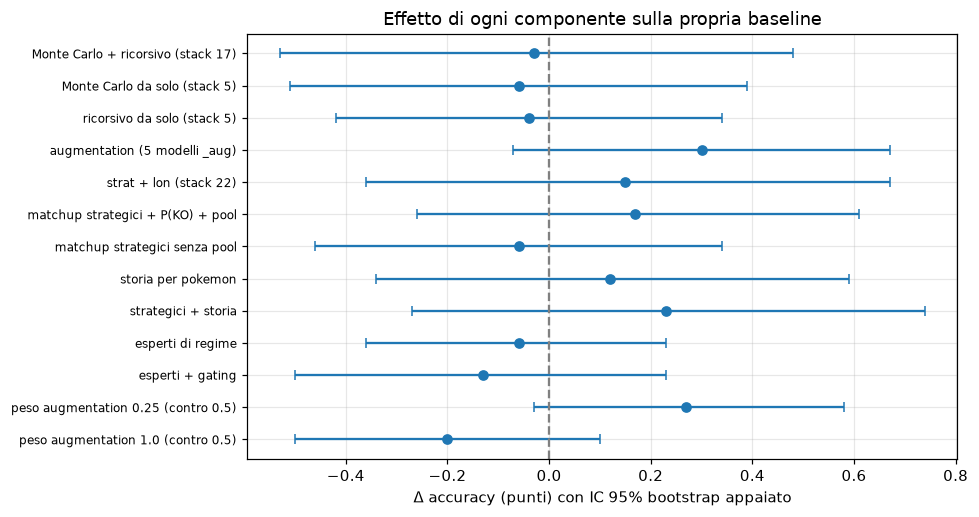

In [11]:
fig, ax = plt.subplots(figsize=(9, 4.8))
yy = np.arange(len(D))[::-1]
ax.errorbar(D["Δ punti"], yy, xerr=[D["Δ punti"] - D["IC lo"], D["IC hi"] - D["Δ punti"]], fmt="o", capsize=3)
ax.axvline(0, color="gray", ls="--"); ax.set_yticks(yy); ax.set_yticklabels(D.componente, fontsize=8)
ax.set(xlabel="Δ accuracy (punti) con IC 95% bootstrap appaiato", title="Effetto di ogni componente sulla propria baseline")
plt.tight_layout(); plt.show()

**Lettura:**

- **Nessun componente** ha un IC appaiato tutto sopra lo zero.
- L'**augmentation** è il più vicino (+0.30 punti, p ≈ 0.12) ed è anche il più semplice: riusa le feature esistenti sui turni 24/26/28.
- **Monte Carlo e ricorsivo:** nello stack v3 a 17 modelli il guadagno è nullo (−0.03). Migliorano di circa +0.3 punti alcuni modelli singoli, ma l'informazione è già nell'ensemble. Costano circa 5 minuti di calcolo e la parte più complessa del codice.
- **Matchup strategici, pool dei team, storia per pokemon:** +0.1/+0.2 punti, non dimostrabili. La storia per pokemon è l'unica economica (14 s).
- **Esperti di regime** e **peso 1.0 dell'augmentation** peggiorano. Il peso 0.25 sembra meglio nello stack a 3 modelli (p ≈ 0.10) ma non nello stack completo.

## 7. Fold e ripetizioni

Tre configurazioni dei base model (22 modelli, feature + mc + rec), stesso meta valutato con gli stessi split. Le OOF hanno split diversi tra le configurazioni, quindi il confronto appaiato riguarda la stessa battaglia ma con modelli addestrati su partizioni diverse.

In [12]:
rows = []
ok0 = None
for d, sec in (("outputs/oof_mc_rec", "stacking folds=5 repeats=1"), ("outputs/oof_mc_rec_k10r1", "stacking folds=10 repeats=1"),
               ("outputs/oof_mc_rec_k5r3", "stacking folds=5 repeats=3")):
    Pd = load_oof(d); a, sd, pm_ = meta_cv(to_Z(Pd, sorted(Pd)), y); ok = (pm_ > .5) == y
    if ok0 is None: ok0 = ok
    dd, lo, hi = paired_bootstrap(ok0, ok)
    rows.append((sec.replace("stacking ", ""), a, sd, dd * 100, lo * 100, hi * 100, TOTALS.get(sec, np.nan) / 60))
pd.DataFrame(rows, columns=["configurazione", "meta acc", "sd", "Δ vs 5x1", "IC lo", "IC hi", "tempo min"]).style.format(
    {"meta acc": "{:.4f}", "sd": "{:.4f}", "Δ vs 5x1": "{:+.2f}", "IC lo": "{:+.2f}", "IC hi": "{:+.2f}", "tempo min": "{:.1f}"})

,configurazione,meta acc,sd,Δ vs 5x1,IC lo,IC hi,tempo min
0,folds=5 repeats=1,0.6981,0.0106,+0.00,+0.00,+0.00,9.5
1,folds=10 repeats=1,0.6952,0.0107,-0.29,-0.72,+0.14,20.6
2,folds=5 repeats=3,0.6941,0.0115,-0.41,-0.83,+0.02,28.2


**Lettura:** né 10 fold né 3 ripetizioni migliorano lo stack: entrambi sono peggiori (non significativamente) e costano 2-3 volte il tempo. Il bagging delle ripetizioni migliora i singoli modelli ma rende le OOF più simili tra loro, togliendo diversità al meta.

## 8. Quadro riassuntivo: resa contro spesa

Verdetto automatico per componente:

- **conviene** se l'IC appaiato è tutto sopra lo zero;
- **neutro, economico** se l'IC contiene lo zero ma il costo è basso (< 1 min) e la stima puntuale è ≥ 0;
- **guadagno non dimostrato** se l'IC contiene lo zero, la stima è positiva ma il costo è alto;
- **non conviene** se la stima è negativa.

In [13]:
def verdict(r):
    if r["IC lo"] > 0: return "conviene"
    if r["Δ punti"] < 0: return "non conviene"
    return "neutro, economico" if r["costo s"] < 60 else "guadagno non dimostrato"
S = D.copy(); S["verdetto"] = S.apply(verdict, axis=1)
S["punti per minuto"] = np.where(S["costo s"] > 0, S["Δ punti"] / (S["costo s"] / 60), np.nan)
print(f"stack completo 22 modelli: {acc_s:.4f} (base model {sum(T.values())/60:.1f} min)  |  "
      f"stack ridotto annidato: {ok_s.mean():.4f} ({t_small/60:.1f} min)")
S[["componente", "Δ punti", "IC lo", "IC hi", "McNemar p", "costo s", "punti per minuto", "verdetto"]].style.format(
    {"Δ punti": "{:+.2f}", "IC lo": "{:+.2f}", "IC hi": "{:+.2f}", "McNemar p": "{:.3f}", "costo s": "{:.0f}", "punti per minuto": "{:+.2f}"})

stack completo 22 modelli: 0.6981 (base model 9.5 min)  |  stack ridotto annidato: 0.6924 (1.5 min)


,componente,Δ punti,IC lo,IC hi,McNemar p,costo s,punti per minuto,verdetto
0,Monte Carlo + ricorsivo (stack 17),-0.03,-0.53,+0.48,0.938,312,-0.01,non conviene
1,Monte Carlo da solo (stack 5),-0.06,-0.51,+0.39,0.829,190,-0.02,non conviene
2,ricorsivo da solo (stack 5),-0.04,-0.42,+0.34,0.876,122,-0.02,non conviene
3,augmentation (5 modelli _aug),+0.30,-0.07,+0.67,0.120,214,+0.08,guadagno non dimostrato
4,strat + lon (stack 22),+0.15,-0.36,+0.67,0.597,135,+0.07,guadagno non dimostrato
5,matchup strategici + P(KO) + pool,+0.17,-0.26,+0.61,0.465,121,+0.08,guadagno non dimostrato
6,matchup strategici senza pool,-0.06,-0.46,+0.34,0.807,121,-0.03,non conviene
7,storia per pokemon,+0.12,-0.34,+0.59,0.641,14,+0.51,"neutro, economico"
8,strategici + storia,+0.23,-0.27,+0.74,0.385,135,+0.10,guadagno non dimostrato
9,esperti di regime,-0.06,-0.36,+0.23,0.747,45,-0.08,non conviene


## Conclusioni

- **Ensemble:** è l'unica scelta con una resa dimostrata. Lo stack batte in modo significativo il miglior modello singolo (+0.6 punti) e, soprattutto, i sottoinsiemi economici (+0.6/+0.9 punti). Il meta-modello logreg in sé aggiunge poco rispetto alla media semplice, ma costa secondi.
- **Quali base model:** contano la diversità, non il numero né l'accuratezza individuale. ExtraTrees, RF e i CatBoost con augmentation, pur costosi e meno accurati da soli, sono quelli che contribuiscono di più. SVM, i GMM, lgbm/xgb/catboost senza augmentation e le varianti con rumore sono ridondanti: si possono togliere risparmiando circa il 40% del tempo, senza perdite misurabili (da confermare con una valutazione annidata).
- **Augmentation con snapshot:** il componente con il miglior rapporto resa/spesa (+0.3 punti, al limite della significatività, costo circa 3.5 minuti).
- **Monte Carlo e modello ricorsivo:** nessun guadagno misurabile nello stack, a fronte del costo maggiore (5 minuti e la parte più complessa del codice). Hanno valore come strumento di analisi, non come leva di accuratezza.
- **Matchup strategici, pool dei team, storia per pokemon:** segnale reale ma ridondante (+0.1/+0.2, non dimostrabile). Solo la storia per pokemon è abbastanza economica da poterla tenere senza rimpianti.
- **Esperti di regime, 10 fold, ripetizioni del k-fold:** spesa senza resa, da non usare.
- **In sintesi:** il tetto non dipende dai modelli. Con questi dati nessuna aggiunta oltre l'ensemble di modelli diversi e l'augmentation ha una resa che giustifica la spesa.